# Exploratory Data Analysis: Supermarket Sales Data

Dataset: https://www.kaggle.com/datasets/yapwh1208/supermarket-sales-data

Analisis empat annex terkait: transaksi, kategori produk, harga grosir harian, dan tingkat susut.

## 1. Setup dan Load Data

Mode default mengunggah empat CSV di Colab. Pilihan lain: `kagglehub`, `kaggle_api`, atau `local` untuk file di folder kerja.

In [1]:
from pathlib import Path
import shutil
import subprocess
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")
LOAD_METHOD = "upload"  # upload, kagglehub, kaggle_api, atau local
DATASET_SLUG = "yapwh1208/supermarket-sales-data"
DATA_DIR = Path.cwd()


In [2]:
if LOAD_METHOD == "upload":
    try:
        from google.colab import files
        print("Pilih keempat file annex1.csv sampai annex4.csv.")
        files.upload()
        DATA_DIR = Path.cwd()
    except ImportError:
        print("Colab tidak terdeteksi; membaca CSV dari folder kerja lokal.")
elif LOAD_METHOD == "kagglehub":
    try:
        import kagglehub
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
        import kagglehub
    DATA_DIR = Path(kagglehub.dataset_download(DATASET_SLUG))
elif LOAD_METHOD == "kaggle_api":
    try:
        from google.colab import files
    except ImportError as exc:
        raise RuntimeError("Mode kaggle_api disiapkan untuk Google Colab.") from exc
    credential_dir = Path.home() / ".kaggle"
    credential_dir.mkdir(parents=True, exist_ok=True)
    credential_path = credential_dir / "kaggle.json"
    if not credential_path.exists():
        print("Unggah kaggle.json dari akun Kaggle; jangan menulis token di notebook.")
        files.upload()
        uploaded_credential = Path.cwd() / "kaggle.json"
        if not uploaded_credential.exists():
            raise FileNotFoundError("kaggle.json tidak ditemukan setelah upload.")
        shutil.copy2(uploaded_credential, credential_path)
    credential_path.chmod(0o600)
    try:
        subprocess.run(["kaggle", "--version"], check=True, capture_output=True)
    except (FileNotFoundError, subprocess.CalledProcessError):
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kaggle"])
    DATA_DIR = Path("/content/supermarket_sales")
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    subprocess.run(["kaggle", "datasets", "download", "-d", DATASET_SLUG, "--unzip", "-p", str(DATA_DIR)], check=True)
elif LOAD_METHOD == "local":
    DATA_DIR = Path.cwd()
else:
    raise ValueError("LOAD_METHOD harus upload, kagglehub, kaggle_api, atau local.")

csv_paths = {}
for annex_number in range(1, 5):
    filename = f"annex{annex_number}.csv"
    matches = list(DATA_DIR.rglob(filename))
    if not matches:
        raise FileNotFoundError(f"{filename} tidak ditemukan di {DATA_DIR}.")
    csv_paths[filename] = matches[0]

print("File yang digunakan:")
for filename, path in csv_paths.items():
    print(f"- {filename}: {path}")

# Kode barang adalah identifier teks, bukan besaran numerik.
raw_tables = {
    "produk": pd.read_csv(csv_paths["annex1.csv"], dtype={"Item Code": "string", "Category Code": "string"}),
    "transaksi": pd.read_csv(csv_paths["annex2.csv"], dtype={"Item Code": "string"}),
    "grosir": pd.read_csv(csv_paths["annex3.csv"], dtype={"Item Code": "string"}),
    "susut": pd.read_csv(csv_paths["annex4.csv"], dtype={"Item Code": "string"}),
}


Colab tidak terdeteksi; membaca CSV dari folder kerja lokal.


File yang digunakan:
- annex1.csv: c:\Users\mfthl\OneDrive\Dokumen\Semester 3\Pak Masri\data-supermarket\annex1.csv
- annex2.csv: c:\Users\mfthl\OneDrive\Dokumen\Semester 3\Pak Masri\data-supermarket\annex2.csv
- annex3.csv: c:\Users\mfthl\OneDrive\Dokumen\Semester 3\Pak Masri\data-supermarket\annex3.csv
- annex4.csv: c:\Users\mfthl\OneDrive\Dokumen\Semester 3\Pak Masri\data-supermarket\annex4.csv


## Ringkasan Awal

Tinjau contoh baris, ukuran, struktur, dan tipe kolom sebelum pembersihan.

In [3]:
for nama_tabel, tabel in raw_tables.items():
    print(f"\n--- {nama_tabel.upper()} | shape={tabel.shape} ---")
    display(tabel.head())
    tabel.info()
    display(tabel.dtypes.rename("dtype").to_frame())



--- PRODUK | shape=(251, 4) ---


,Item Code,Item Name,Category Code,Category Name
0,102900005115168,Niushou Shengcai,1011010101,Flower/Leaf Vegetables
1,102900005115199,Sichuan Red Cedar,1011010101,Flower/Leaf Vegetables
2,102900005115625,Local Xiaomao Cabbage,1011010101,Flower/Leaf Vegetables
3,102900005115748,White Caitai,1011010101,Flower/Leaf Vegetables
4,102900005115762,Amaranth,1011010101,Flower/Leaf Vegetables


<class 'pandas.DataFrame'>
RangeIndex: 251 entries, 0 to 250
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Item Code      251 non-null    string
 1   Item Name      251 non-null    str   
 2   Category Code  251 non-null    string
 3   Category Name  251 non-null    str   
dtypes: str(2), string(2)
memory usage: 8.0 KB


,dtype
Item Code,string
Item Name,str
Category Code,string
Category Name,str



--- TRANSAKSI | shape=(878503, 7) ---


...

,dtype
Date,str
Item Code,string
Wholesale Price (RMB/kg),float64



--- SUSUT | shape=(251, 3) ---


,Item Code,Item Name,Loss Rate (%)
0,102900005115168,Niushou Shengcai,4.39
1,102900005115199,Sichuan Red Cedar,10.46
2,102900005115250,Xixia Black Mushroom (1),10.80
3,102900005115625,Local Xiaomao Cabbage,0.18
4,102900005115748,White Caitai,8.78


<class 'pandas.DataFrame'>
RangeIndex: 251 entries, 0 to 250
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Item Code      251 non-null    string 
 1   Item Name      251 non-null    str    
 2   Loss Rate (%)  251 non-null    float64
dtypes: float64(1), str(1), string(1)
memory usage: 6.0 KB


,dtype
Item Code,string
Item Name,str
Loss Rate (%),float64


## 2. Data Cleaning dan Tipe Data

Periksa nilai kosong dan duplikat. Baris tanpa identifier/tanggal kunci dihapus karena tidak dapat ditautkan dengan andal. Nilai numerik non-kunci yang kosong diisi median agar lebih tahan terhadap nilai ekstrem; nilai kategorik diisi modus. Identifier tidak pernah diimputasi.

In [4]:
quality_rows = []
for nama_tabel, tabel in raw_tables.items():
    for kolom in tabel.columns:
        jumlah_kosong = int(tabel[kolom].isna().sum())
        quality_rows.append({
            "Tabel": nama_tabel,
            "Kolom": kolom,
            "Missing": jumlah_kosong,
            "Missing (%)": 100 * jumlah_kosong / max(len(tabel), 1),
            "Tipe awal": str(tabel[kolom].dtype),
        })

display(pd.DataFrame(quality_rows))
display(pd.DataFrame([
    {"Tabel": nama_tabel, "Baris": len(tabel), "Duplikat penuh": int(tabel.duplicated().sum())}
    for nama_tabel, tabel in raw_tables.items()
]))


,Tabel,Kolom,Missing,Missing (%),Tipe awal
0,produk,Item Code,0,0.0,string
1,produk,Item Name,0,0.0,str
2,produk,Category Code,0,0.0,string
3,produk,Category Name,0,0.0,str
4,transaksi,Date,0,0.0,str
5,transaksi,Time,0,0.0,str
6,transaksi,Item Code,0,0.0,string
7,transaksi,Quantity Sold (kilo),0,0.0,float64
8,transaksi,Unit Selling Price (RMB/kg),0,0.0,float64
9,transaksi,Sale or Return,0,0.0,str


,Tabel,Baris,Duplikat penuh
0,produk,251,0
1,transaksi,878503,0
2,grosir,55982,0
3,susut,251,0


In [5]:
key_columns = {
    "produk": ["Item Code"],
    "transaksi": ["Date", "Time", "Item Code"],
    "grosir": ["Date", "Item Code"],
    "susut": ["Item Code"],
}
numeric_columns = {
    "transaksi": ["Quantity Sold (kilo)", "Unit Selling Price (RMB/kg)"],
    "grosir": ["Wholesale Price (RMB/kg)"],
    "susut": ["Loss Rate (%)"],
}
clean_tables = {}
cleaning_log = []

for nama_tabel, tabel_asli in raw_tables.items():
    tabel = tabel_asli.copy()
    baris_awal = len(tabel)
    duplikat_dihapus = int(tabel.duplicated().sum())
    tabel = tabel.drop_duplicates().copy()
    tabel["Item Code"] = tabel["Item Code"].astype("string").str.strip().replace("", pd.NA)
    if "Date" in tabel.columns:
        tabel["Date"] = pd.to_datetime(tabel["Date"], errors="coerce")
    if "Time" in tabel.columns:
        # Simpan waktu sebagai timedelta agar nilai jam-menit-detik dapat diproses konsisten.
        tabel["Time"] = pd.to_timedelta(tabel["Time"], errors="coerce")

    sebelum_key = len(tabel)
    tabel = tabel.dropna(subset=key_columns[nama_tabel]).copy()
    key_dihapus = sebelum_key - len(tabel)
    imputasi = 0

    for kolom in tabel.columns:
        if kolom in key_columns[nama_tabel]:
            continue
        if kolom in numeric_columns.get(nama_tabel, []):
            tabel[kolom] = pd.to_numeric(tabel[kolom], errors="coerce")
        kosong = int(tabel[kolom].isna().sum())
        if kosong == 0:
            continue
        if pd.api.types.is_numeric_dtype(tabel[kolom]):
            nilai_pengganti = tabel[kolom].median()
            if pd.notna(nilai_pengganti):
                tabel[kolom] = tabel[kolom].fillna(nilai_pengganti)
                imputasi += kosong
        else:
            modus = tabel[kolom].mode(dropna=True)
            if not modus.empty:
                tabel[kolom] = tabel[kolom].fillna(modus.iloc[0])
                imputasi += kosong

    if "Category Name" in tabel.columns:
        tabel["Category Name"] = tabel["Category Name"].astype("string").str.replace("\u00a0", " ", regex=False).str.strip()
    if "Sale or Return" in tabel.columns:
        tabel["Sale or Return"] = tabel["Sale or Return"].astype("string").str.strip().str.lower()
    if "Discount (Yes/No)" in tabel.columns:
        tabel["Discount (Yes/No)"] = tabel["Discount (Yes/No)"].astype("string").str.strip().str.title()

    clean_tables[nama_tabel] = tabel
    cleaning_log.append({
        "Tabel": nama_tabel, "Baris awal": baris_awal,
        "Duplikat dihapus": duplikat_dihapus,
        "Baris tanpa kunci dihapus": key_dihapus,
        "Nilai non-kunci diimputasi": imputasi,
        "Baris akhir": len(tabel),
    })

display(pd.DataFrame(cleaning_log))


,Tabel,Baris awal,Duplikat dihapus,Baris tanpa kunci dihapus,Nilai non-kunci diimputasi,Baris akhir
0,produk,251,0,0,0,251
1,transaksi,878503,0,0,0,878503
2,grosir,55982,0,0,0,55982
3,susut,251,0,0,0,251


## 3. Validasi Relasi dan Penggabungan

Gunakan `Item Code` sebagai kunci produk dan pasangan `(Date, Item Code)` untuk harga grosir. Pastikan tabel sisi kanan unik dan gunakan `validate='many_to_one'` agar join tidak menggandakan transaksi. Nama produk tidak dipakai sebagai kunci.

In [6]:
produk = clean_tables["produk"]
transaksi = clean_tables["transaksi"]
grosir = clean_tables["grosir"]
susut = clean_tables["susut"]

if not produk["Item Code"].is_unique:
    raise ValueError("Item Code pada annex1 tidak unik; join dapat menggandakan transaksi.")
if not susut["Item Code"].is_unique:
    raise ValueError("Item Code pada annex4 tidak unik; join dapat menggandakan transaksi.")
if grosir.duplicated(["Date", "Item Code"]).any():
    raise ValueError("Pasangan Date + Item Code pada annex3 tidak unik.")

produk_susut = produk.merge(
    susut[["Item Code", "Loss Rate (%)"]],
    on="Item Code", how="left", validate="one_to_one",
)
data_analisis = transaksi.merge(
    produk_susut[["Item Code", "Item Name", "Category Name", "Loss Rate (%)"]],
    on="Item Code", how="left", validate="many_to_one",
).merge(
    grosir[["Date", "Item Code", "Wholesale Price (RMB/kg)"]],
    on=["Date", "Item Code"], how="left", validate="many_to_one",
)

if len(data_analisis) != len(transaksi):
    raise ValueError("Jumlah baris berubah setelah join; periksa kunci tabel.")
print(f"Transaksi dipertahankan: {len(data_analisis):,} dari {len(transaksi):,} baris.")
print(f"Cakupan kategori produk: {data_analisis['Category Name'].notna().mean():.2%}")
print(f"Cakupan harga grosir harian: {data_analisis['Wholesale Price (RMB/kg)'].notna().mean():.2%}")

display(transaksi["Sale or Return"].value_counts(dropna=False).rename_axis("Status").reset_index(name="Jumlah baris"))
jumlah_retur = int(transaksi["Sale or Return"].eq("return").sum())
retur_negatif = int((transaksi.loc[transaksi["Sale or Return"].eq("return"), "Quantity Sold (kilo)"] < 0).sum())
print(f"Retur: {jumlah_retur:,} baris; retur dengan jumlah negatif: {retur_negatif:,}. Semua retur tetap ada di data gabungan.")

# Retur tercatat dengan jumlah negatif, jadi dipisahkan dari distribusi penjualan utama.
penjualan = data_analisis.loc[data_analisis["Sale or Return"].eq("sale")].copy()
print(f"Baris penjualan untuk statistik utama: {len(penjualan):,}.")


Transaksi dipertahankan: 878,503 dari 878,503 baris.
Cakupan kategori produk: 100.00%
Cakupan harga grosir harian: 100.00%


,Status,Jumlah baris
0,sale,878042
1,return,461


Retur: 461 baris; retur dengan jumlah negatif: 461. Semua retur tetap ada di data gabungan.


Baris penjualan untuk statistik utama: 878,042.


## 4. Statistik Deskriptif dan Outlier IQR

Statistik kuantitas dan harga jual dihitung pada transaksi penjualan; harga grosir dan tingkat susut dihitung dari tabel masing-masing. Batas outlier: Q1 − 1,5×IQR dan Q3 + 1,5×IQR. Outlier perlu ditinjau, bukan otomatis kesalahan.

In [7]:
metric_specs = {
    "Jumlah terjual (kg)": (penjualan, "Quantity Sold (kilo)", ["Date", "Time", "Item Code", "Item Name", "Category Name"]),
    "Harga jual (RMB/kg)": (penjualan, "Unit Selling Price (RMB/kg)", ["Date", "Item Code", "Item Name", "Category Name"]),
    "Harga grosir (RMB/kg)": (grosir, "Wholesale Price (RMB/kg)", ["Date", "Item Code"]),
    "Tingkat susut (%)": (susut, "Loss Rate (%)", ["Item Code", "Item Name"]),
}
stat_rows, outlier_rows, outlier_examples = [], [], {}

for nama_metrik, (tabel, kolom, id_columns) in metric_specs.items():
    nilai = tabel[kolom].dropna()
    q1, q3 = nilai.quantile([0.25, 0.75])
    iqr = q3 - q1
    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr
    mask_outlier = tabel[kolom].lt(batas_bawah) | tabel[kolom].gt(batas_atas)
    jumlah_outlier = int(mask_outlier.sum())
    stat_rows.append({
        "Metrik": nama_metrik, "N": int(nilai.size), "Mean": nilai.mean(),
        "Median": nilai.median(), "Standar deviasi": nilai.std(),
    })
    outlier_rows.append({
        "Metrik": nama_metrik, "Q1": q1, "Q3": q3, "IQR": iqr,
        "Batas bawah": batas_bawah, "Batas atas": batas_atas,
        "Jumlah outlier": jumlah_outlier,
        "Outlier (%)": 100 * jumlah_outlier / max(len(nilai), 1),
    })
    kolom_contoh = [c for c in id_columns if c in tabel.columns] + [kolom]
    outlier_examples[nama_metrik] = tabel.loc[mask_outlier, kolom_contoh].head(5)

display(pd.DataFrame(stat_rows).round(3))
display(pd.DataFrame(outlier_rows).round(3))
for nama_metrik, contoh in outlier_examples.items():
    print(f"\nContoh maksimal 5 outlier — {nama_metrik}:")
    display(contoh)


,Metrik,N,Mean,Median,Standar deviasi
0,Jumlah terjual (kg),878042,0.537,0.435,0.399
1,Harga jual (RMB/kg),878042,8.917,7.900,6.311
2,Harga grosir (RMB/kg),55982,5.963,4.630,5.068
3,Tingkat susut (%),251,9.427,9.430,5.211


,Metrik,Q1,Q3,IQR,Batas bawah,Batas atas,Jumlah outlier,Outlier (%)
0,Jumlah terjual (kg),0.290,0.742,0.452,-0.388,1.420,10570,1.204
1,Harga jual (RMB/kg),4.900,10.800,5.900,-3.950,19.650,61842,7.043
2,Harga grosir (RMB/kg),2.810,7.570,4.760,-4.330,14.710,2586,4.619
3,Tingkat susut (%),8.225,11.130,2.905,3.867,15.488,60,23.904



Contoh maksimal 5 outlier — Jumlah terjual (kg):


,Date,Time,Item Code,Item Name,Category Name,Quantity Sold (kilo)
719,2020-07-01,0 days 18:18:45.372000,102900011008522,Sweet Chinese Cabbage,Flower/Leaf Vegetables,1.554
842,2020-07-01,0 days 19:13:16.670000,102900005116509,Green Eggplant (1),Solanum,1.432
1390,2020-07-02,0 days 14:25:20.201000,102900005118831,Wawacai,Flower/Leaf Vegetables,2.000
1545,2020-07-02,0 days 17:24:21.153000,102900005117056,Paopaojiao (Jingpin),Capsicum,1.794
3463,2020-07-04,0 days 12:07:35.079000,102900005116509,Green Eggplant (1),Solanum,1.482



Contoh maksimal 5 outlier — Harga jual (RMB/kg):


,Date,Item Code,Item Name,Category Name,Unit Selling Price (RMB/kg)
49,2020-07-01,102900051000944,Honghu Lotus Root,Aquatic Tuberous Vegetables,39.8
94,2020-07-01,102900005125808,Millet Pepper,Capsicum,25.8
96,2020-07-01,102900005125808,Millet Pepper,Capsicum,25.8
110,2020-07-01,102900005125808,Millet Pepper,Capsicum,25.8
130,2020-07-01,102900005125808,Millet Pepper,Capsicum,25.8



Contoh maksimal 5 outlier — Harga grosir (RMB/kg):


,Date,Item Code,Wholesale Price (RMB/kg)
33,2020-07-01,102900051000944,29.43
71,2020-07-02,102900051000944,29.54
141,2020-07-04,102900051000944,25.48
434,2020-07-12,102900051000944,24.05
763,2020-07-21,102900051000944,20.00



Contoh maksimal 5 outlier — Tingkat susut (%):


,Item Code,Item Name,Loss Rate (%)
3,102900005115625,Local Xiaomao Cabbage,0.18
5,102900005115762,Amaranth,18.52
14,102900005115885,Caidian Quinoa Artemisia,0.47
17,102900005115960,Chinese Cabbage,22.27
27,102900005116547,Needle Mushroom (1),3.43


## 5. Visualisasi dan Interpretasi

Tiga grafik memakai jumlah transaksi, bukan pendapatan. Histogram dan boxplot dibatasi sampai persentil ke-99 agar pola utama terbaca; statistik dan outlier tetap memakai seluruh data. Setiap PNG disimpan ke `figures/` dengan dpi 300.

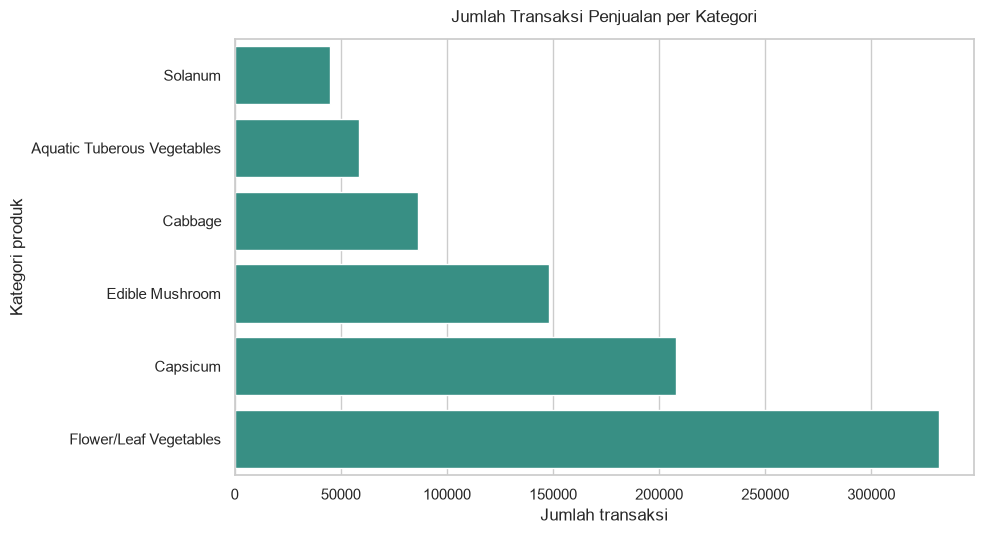

Interpretasi grafik 1: kategori Flower/Leaf Vegetables paling sering muncul, sebanyak 331,789 transaksi (37.8% dari seluruh penjualan). Kategori Capsicum menyusul dengan 23.7%; angka ini frekuensi, bukan pendapatan.


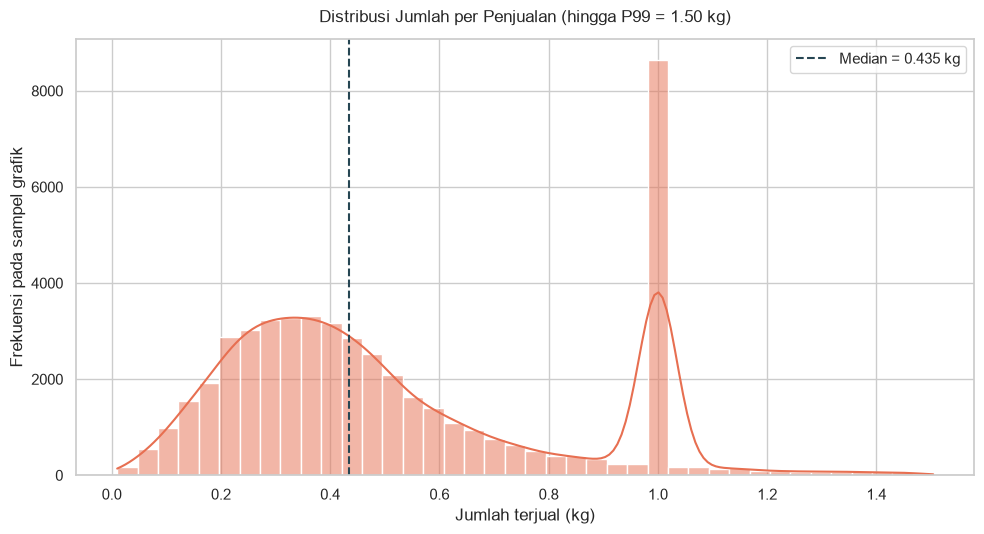

Interpretasi grafik 2: median kuantitas 0.435 kg dan mean 0.537 kg; pola ini menceng ke kanan. Tampilan dibatasi pada P99 agar mayoritas transaksi terlihat; nilai di atas P99 tetap masuk ke statistik dan pemeriksaan outlier.


C:\Users\mfthl\AppData\Local\Temp\ipykernel_22404\1584637663.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


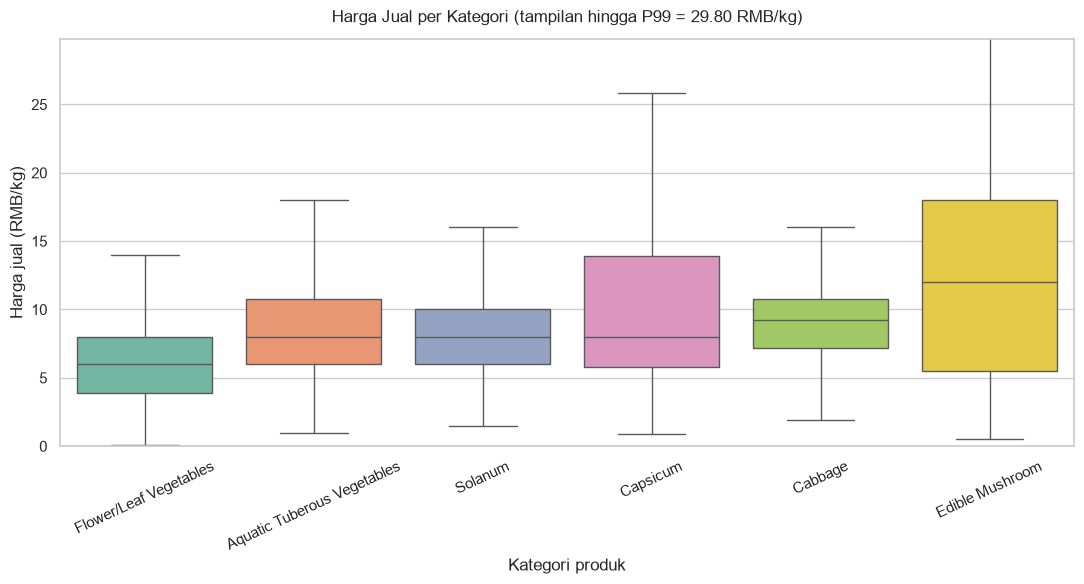

Interpretasi grafik 3: median harga terendah ada pada Flower/Leaf Vegetables (6.00 RMB/kg), sedangkan tertinggi pada Edible Mushroom (12.00 RMB/kg). Ini membandingkan harga tipikal, bukan laba atau pendapatan.
PNG tersimpan:
- figures\grafik_1_transaksi_per_kategori.png
- figures\grafik_2_distribusi_kuantitas.png
- figures\grafik_3_harga_per_kategori.png


In [8]:
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Grafik 1: jumlah baris penjualan per kategori.
jumlah_kategori = penjualan["Category Name"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(x=jumlah_kategori.values, y=jumlah_kategori.index, color="#2A9D8F", ax=ax)
ax.set_title("Jumlah Transaksi Penjualan per Kategori", pad=12)
ax.set_xlabel("Jumlah transaksi")
ax.set_ylabel("Kategori produk")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "grafik_1_transaksi_per_kategori.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

total_penjualan = len(penjualan)
kategori_teratas = jumlah_kategori.idxmax()
persen_teratas = 100 * jumlah_kategori.max() / total_penjualan
kategori_kedua = jumlah_kategori.sort_values(ascending=False).index[1]
persen_kedua = 100 * jumlah_kategori[kategori_kedua] / total_penjualan
print(
    f"Interpretasi grafik 1: kategori {kategori_teratas} paling sering muncul, "
    f"sebanyak {jumlah_kategori.max():,} transaksi ({persen_teratas:.1f}% dari seluruh penjualan). "
    f"Kategori {kategori_kedua} menyusul dengan {persen_kedua:.1f}%; angka ini frekuensi, bukan pendapatan."
)

# Grafik 2: tampilkan sampai P99 dan gunakan sampel deterministik untuk KDE yang ringan.
kolom_kuantitas = "Quantity Sold (kilo)"
kuantitas = penjualan[kolom_kuantitas].dropna()
batas_p99_kuantitas = kuantitas.quantile(0.99)
sampel_grafik = kuantitas.loc[kuantitas <= batas_p99_kuantitas]
sampel_grafik = sampel_grafik.sample(n=min(50000, len(sampel_grafik)), random_state=42)
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.histplot(sampel_grafik, bins=40, kde=True, color="#E76F51", ax=ax)
ax.axvline(kuantitas.median(), color="#264653", linestyle="--", label=f"Median = {kuantitas.median():.3f} kg")
ax.set_title(f"Distribusi Jumlah per Penjualan (hingga P99 = {batas_p99_kuantitas:.2f} kg)", pad=12)
ax.set_xlabel("Jumlah terjual (kg)")
ax.set_ylabel("Frekuensi pada sampel grafik")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "grafik_2_distribusi_kuantitas.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

mean_kuantitas, median_kuantitas = kuantitas.mean(), kuantitas.median()
bentuk_distribusi = "menceng ke kanan" if mean_kuantitas > median_kuantitas else "tidak menunjukkan mean lebih besar dari median"
print(
    f"Interpretasi grafik 2: median kuantitas {median_kuantitas:.3f} kg dan mean {mean_kuantitas:.3f} kg; "
    f"pola ini {bentuk_distribusi}. Tampilan dibatasi pada P99 agar mayoritas transaksi terlihat; "
    "nilai di atas P99 tetap masuk ke statistik dan pemeriksaan outlier."
)

# Grafik 3: boxplot harga jual per kategori; fliers diringkas terpisah dengan metode IQR.
kolom_harga = "Unit Selling Price (RMB/kg)"
median_harga_kategori = penjualan.groupby("Category Name")[kolom_harga].median().sort_values()
urut_kategori = median_harga_kategori.index.tolist()
batas_p99_harga = penjualan[kolom_harga].quantile(0.99)
fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(
    data=penjualan, x="Category Name", y=kolom_harga, order=urut_kategori,
    palette=sns.color_palette("Set2", n_colors=len(urut_kategori)), showfliers=False, ax=ax,
)
ax.set_ylim(0, batas_p99_harga)
ax.set_title(f"Harga Jual per Kategori (tampilan hingga P99 = {batas_p99_harga:.2f} RMB/kg)", pad=12)
ax.set_xlabel("Kategori produk")
ax.set_ylabel("Harga jual (RMB/kg)")
ax.tick_params(axis="x", rotation=25)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "grafik_3_harga_per_kategori.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(
    f"Interpretasi grafik 3: median harga terendah ada pada {median_harga_kategori.index[0]} "
    f"({median_harga_kategori.iloc[0]:.2f} RMB/kg), sedangkan tertinggi pada {median_harga_kategori.index[-1]} "
    f"({median_harga_kategori.iloc[-1]:.2f} RMB/kg). Ini membandingkan harga tipikal, bukan laba atau pendapatan."
)
print("PNG tersimpan:")
for path in sorted(FIGURE_DIR.glob("*.png")):
    print(f"- {path}")


## 6. Peluang Sederhana

Peluang empiris transaksi mendapat diskon dihitung dari seluruh baris transaksi. Ini adalah proporsi deskriptif, bukan bukti bahwa diskon menyebabkan perubahan penjualan.

In [9]:
jumlah_transaksi_total = len(transaksi)
jumlah_diskon = int(transaksi["Discount (Yes/No)"].eq("Yes").sum())
probabilitas_diskon = jumlah_diskon / jumlah_transaksi_total if jumlah_transaksi_total else np.nan
print("P(diskon = Ya) = jumlah transaksi diskon / seluruh transaksi")
print(f"P(diskon = Ya) = {jumlah_diskon:,} / {jumlah_transaksi_total:,} = {probabilitas_diskon:.4f} ({probabilitas_diskon:.2%})")
print("Kesimpulan: sekitar 5 dari setiap 100 baris transaksi tercatat mendapat diskon; proporsi ini tidak membuktikan dampak diskon terhadap penjualan.")


P(diskon = Ya) = jumlah transaksi diskon / seluruh transaksi
P(diskon = Ya) = 47,366 / 878,503 = 0.0539 (5.39%)
Kesimpulan: sekitar 5 dari setiap 100 baris transaksi tercatat mendapat diskon; proporsi ini tidak membuktikan dampak diskon terhadap penjualan.


## 7. Kesimpulan

Temuan dirangkum dari nilai hasil hitung agar tetap sesuai saat notebook dijalankan ulang. Saat presentasi, bedakan jumlah transaksi dari pendapatan dan jelaskan bahwa outlier perlu ditinjau berdasarkan konteks bisnis.

In [10]:
tanggal_awal = transaksi["Date"].min().date()
tanggal_akhir = transaksi["Date"].max().date()
jumlah_penjualan = int(transaksi["Sale or Return"].eq("sale").sum())
jumlah_retur = int(transaksi["Sale or Return"].eq("return").sum())

print("Temuan utama:")
print(f"1. Data mencakup {len(transaksi):,} transaksi pada {tanggal_awal} sampai {tanggal_akhir}; tabel produk berisi {produk['Item Code'].nunique():,} kode produk.")
print(f"2. Kategori {kategori_teratas} menyumbang {persen_teratas:.1f}% dari baris penjualan, berdasarkan frekuensi transaksi.")
print(f"3. Median jumlah per penjualan {median_kuantitas:.3f} kg; mean {mean_kuantitas:.3f} kg, sehingga transaksi besar menarik distribusi ke kanan.")
print(f"4. Terdapat {jumlah_retur:,} baris retur dan {probabilitas_diskon:.2%} transaksi berdiskon; ini temuan deskriptif, bukan bukti sebab-akibat.")


Temuan utama:
1. Data mencakup 878,503 transaksi pada 2020-07-01 sampai 2023-06-30; tabel produk berisi 251 kode produk.
2. Kategori Flower/Leaf Vegetables menyumbang 37.8% dari baris penjualan, berdasarkan frekuensi transaksi.
3. Median jumlah per penjualan 0.435 kg; mean 0.537 kg, sehingga transaksi besar menarik distribusi ke kanan.
4. Terdapat 461 baris retur dan 5.39% transaksi berdiskon; ini temuan deskriptif, bukan bukti sebab-akibat.
